# Проект: Анализ факторов ценообразования и покупательского спроса на Amazon (EDA и сегментация)

## 📌 Бизнес-контекст и задачи
* **Контекст:** На руках имеются данные по более чем 1000 товаров Amazon (включая категории, реальные и дисконтные цены, проценты скидок, пользовательские рейтинги и количество отзывов).
* **Цель:** Выявить ключевые драйверы покупательской активности, оценить влияние величины скидок на объем отзывов/рейтинг и исследовать ценовую структуру по категориям товаров.
* **Основная гипотеза ($H_1$):** Глубина скидки (discount_percentage) и ценовой сегмент товара оказывают статистически значимое влияние на уровень вовлеченности покупателей (выраженный через rating_count), при этом товары с высоким дисконтом в категории Computers&Accessories генерируют наибольшее число отзывов.

# 1. Подготовка данных

Импорт необходимых библиотек и загрузка датасета.

In [4]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st
import warnings

warnings.simplefilter(action='ignore', category=FutureWarning) #отключаю ненужные уведомления

sns.set_theme(style="whitegrid") #сразу ставлю сетку для всех графиков

# Загрузка данных
url = 'https://raw.githubusercontent.com/sofiaerunova/data-analyst-portfolio/refs/heads/main/projects/amazon-sales-analysis/amazon.csv'
amazon_sales = pd.read_csv(url)
amazon_sales.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [5]:
# Смотрим общую информацию
display(amazon_sales.shape)
print()
amazon_sales.info()

(1465, 16)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product_id           1465 non-null   object
 1   product_name         1465 non-null   object
 2   category             1465 non-null   object
 3   discounted_price     1465 non-null   object
 4   actual_price         1465 non-null   object
 5   discount_percentage  1465 non-null   object
 6   rating               1465 non-null   object
 7   rating_count         1463 non-null   object
 8   about_product        1465 non-null   object
 9   user_id              1465 non-null   object
 10  user_name            1465 non-null   object
 11  review_id            1465 non-null   object
 12  review_title         1465 non-null   object
 13  review_content       1465 non-null   object
 14  img_link             1465 non-null   object
 15  product_link         1465 non-null   object
dtypes: ob

In [6]:
#Чистим значения в столбцах,приводим к нужному типу данных
amazon_sales['discounted_price'] = amazon_sales['discounted_price'].str.replace('₹', '')
amazon_sales['discounted_price'] = amazon_sales['discounted_price'].str.replace(',', '')
amazon_sales['discounted_price'] = amazon_sales['discounted_price'].astype('float64')

amazon_sales['actual_price'] = amazon_sales['actual_price'].str.replace('₹', '')
amazon_sales['actual_price'] = amazon_sales['actual_price'].str.replace(',', '')
amazon_sales['actual_price'] = amazon_sales['actual_price'].astype('float64')

amazon_sales['discount_percentage'] = amazon_sales['discount_percentage'].str.replace('%', '').astype('float64')
amazon_sales['discount_percentage'] = amazon_sales['discount_percentage'] / 100

amazon_sales['rating_count'] = amazon_sales['rating_count'].str.replace(',', '').astype('float64')

In [7]:
#Проверяем пропуски
amazon_sales.isna().sum()

product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           2
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64

In [8]:
# Всего 2 пропуска, можно удалить без вреда для данных
amazon_sales.dropna(axis=0, inplace=True)

In [9]:
# Проверяем дубликаты 
amazon_sales.duplicated().sum()

0

In [10]:
# Проверяем, какие есть оценки
amazon_sales['rating'].value_counts()

rating
4.1    244
4.3    230
4.2    228
4.0    129
3.9    123
4.4    123
3.8     86
4.5     75
4       52
3.7     42
3.6     35
3.5     26
4.6     17
3.3     16
3.4     10
4.7      6
3.1      4
4.8      3
3.2      2
2.8      2
3.0      2
5.0      2
2.3      1
|        1
2        1
3        1
2.6      1
2.9      1
Name: count, dtype: int64

In [11]:
# Смотрим, что за строка со значением rating = '|'
amazon_sales[amazon_sales['rating'] == '|']

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
1279,B08L12N5H1,Eureka Forbes car Vac 100 Watts Powerful Sucti...,"Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cle...",2099.0,2499.0,0.16,|,992.0,No Installation is provided for this product|1...,"AGTDSNT2FKVYEPDPXAA673AIS44A,AER2XFSWNN4LAUCJ5...","Divya,Dr Nefario,Deekshith,Preeti,Prasanth R,P...","R2KKTKM4M9RDVJ,R1O692MZOBTE79,R2WRSEWL56SOS4,R...","Decent product,doesn't pick up sand,Ok ok,Must...","Does the job well,doesn't work on sand. though...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Eureka-Forbes-Vacuum-Cle...


In [12]:
# Перейдём по ссылке товара и посмотрим какой у него рейтинг
link = amazon_sales.loc[amazon_sales['rating'] == '|', 'product_link'].values[0]
link

'https://www.amazon.in/Eureka-Forbes-Vacuum-Cleaner-Washable/dp/B08L12N5H1/ref=sr_1_295?qid=1672923607&s=kitchen&sr=1-295'

In [13]:
# На данный момент рейтинг товара 3.8, меняем | на 3.8 и приводим столбец к нужному типу данных
amazon_sales['rating'] = amazon_sales['rating'].str.replace('|', '3.8').astype('float64')

In [14]:
# Посмотрим описательную статистику по числовым столбцам
amazon_sales.describe().round()

,discounted_price,actual_price,discount_percentage,rating,rating_count
count,1463.0,1463.0,1463.0,1463.0,1463.0
mean,3129.0,5451.0,0.0,4.0,18296.0
std,6948.0,10881.0,0.0,0.0,42754.0
min,39.0,39.0,0.0,2.0,2.0
25%,325.0,800.0,0.0,4.0,1186.0
50%,799.0,1690.0,0.0,4.0,5179.0
75%,1999.0,4312.0,1.0,4.0,17336.0
max,77990.0,139900.0,1.0,5.0,426973.0


In [15]:
# В столбце category категории перечислены через |, это нерепрезентативно
category_split = amazon_sales['category'].str.split('|', expand=True)
category_split

,0,1,2,3,4,5,6
0,Computers&Accessories,Accessories&Peripherals,Cables&Accessories,Cables,USBCables,None,None
1,Computers&Accessories,Accessories&Peripherals,Cables&Accessories,Cables,USBCables,None,None
2,Computers&Accessories,Accessories&Peripherals,Cables&Accessories,Cables,USBCables,None,None
3,Computers&Accessories,Accessories&Peripherals,Cables&Accessories,Cables,USBCables,None,None
4,Computers&Accessories,Accessories&Peripherals,Cables&Accessories,Cables,USBCables,None,None
...,...,...,...,...,...,...,...
1460,Home&Kitchen,Kitchen&HomeAppliances,WaterPurifiers&Accessories,WaterPurifierAccessories,None,None,None
1461,Home&Kitchen,Kitchen&HomeAppliances,SmallKitchenAppliances,Rice&PastaCookers,None,None,None
1462,Home&Kitchen,"Heating,Cooling&AirQuality",RoomHeaters,HeatConvectors,None,None,None
1463,Home&Kitchen,"Heating,Cooling&AirQuality",Fans,ExhaustFans,None,None,None


In [16]:
# Переименуем новые калонки с категориями, я решила оставить первые две колонки с категорией и подкатегорией
category_split = category_split.rename(columns={
    0 : 'main_category',
    1 : 'sub_category'
})

In [17]:
# Создаю копию amazon_sales с нужными мне колонками, куда добавлю новые категории
amazon_sales_2 = amazon_sales[[
    'product_id', 'product_name', 'discounted_price', 
    'actual_price', 'discount_percentage', 'rating', 'rating_count',
    'about_product', 'user_id', 'user_name'
]].copy()

# Добавляем колонки из category_split
amazon_sales_2['main_category'] = category_split['main_category'].values
amazon_sales_2['sub_category'] = category_split['sub_category'].values

In [18]:
# Смотрим, какие у нас есть главные категории
amazon_sales_2['main_category'].value_counts()

main_category
Electronics              526
Computers&Accessories    451
Home&Kitchen             448
OfficeProducts            31
MusicalInstruments         2
HomeImprovement            2
Toys&Games                 1
Car&Motorbike              1
Health&PersonalCare        1
Name: count, dtype: int64

In [19]:
# Привожу значения в главной категории в читаемый формат
amazon_sales_2['main_category'] = amazon_sales_2['main_category'].str.replace('&',' & ')
amazon_sales_2['main_category'] = amazon_sales_2['main_category'].str.replace('OfficeProducts','Office Products')
amazon_sales_2['main_category'] = amazon_sales_2['main_category'].str.replace('MusicalInstruments','Musical Instruments')
amazon_sales_2['main_category'] = amazon_sales_2['main_category'].str.replace('HomeImprovement','Home Improvement')

In [20]:
# Смотрим, какие у нас есть главные подкатегории
amazon_sales_2['sub_category'].value_counts()

sub_category
Accessories&Peripherals                    379
Kitchen&HomeAppliances                     308
HomeTheater,TV&Video                       162
Mobiles&Accessories                        161
Heating,Cooling&AirQuality                 116
WearableTechnology                          76
Headphones,Earbuds&Accessories              66
NetworkingDevices                           34
OfficePaperProducts                         27
ExternalDevices&DataStorage                 18
Cameras&Photography                         16
HomeStorage&Organization                    16
HomeAudio                                   16
GeneralPurposeBatteries&BatteryChargers     14
Accessories                                 14
Printers,Inks&Accessories                   11
CraftMaterials                               7
Components                                   5
OfficeElectronics                            4
Electrical                                   2
Monitors                                     2


In [21]:
# Привожу значения в подкатегории в читаемый формат
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('&',' & ')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace(',',', ')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('HomeAppliances','Home Appliances')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('HomeTheater','Home Theater')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('AirQuality','Air Quality')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('WearableTechnology','Wearable Technology')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('NetworkingDevices','Networking Devices')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('OfficePaperProducts','Office Paper Products')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('ExternalDevices','External Devices')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('DataStorage','Data Storage')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('HomeStorage','Home Storage')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('HomeAudio','Home Audio')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('GeneralPurposeBatteries','General Purpose Batteries')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('BatteryChargers','Battery Chargers')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('CraftMaterials','Craft Materials')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('OfficeElectronics','Office Electronics')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('PowerAccessories','Power Accessories')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('CarAccessories','Car Accessories')
amazon_sales_2['sub_category'] = amazon_sales_2['sub_category'].str.replace('HomeMedicalSupplies','Home Medical Supplies')

In [22]:
# Убираем лишние пробелы в product_id
amazon_sales_2['product_id'] = amazon_sales_2['product_id'].str.strip()

Создадим столбец rating_category по следующиму принципу:
- rating меньше 2, то категория 'critical'
- rating от 2 до 2.9, то категория 'poor'
- rating от 3 до 3.9, то категория 'fair'
- rating от 4 до 4.8, то категория 'good'
- rating от 4.9 до 5, то категория 'excellent'

In [24]:
rating_category = []

for rating in amazon_sales_2['rating']:
    if rating < 2:
        rating_category.append('critical')
    elif rating >= 2 and rating < 3:
        rating_category.append('poor')
    elif rating >= 3 and rating < 4:
        rating_category.append('fair')
    elif rating >= 4 and rating < 4.8:
        rating_category.append('good')
    elif rating >= 4.8:
        rating_category.append('excellent')

In [25]:
amazon_sales_2['rating_category'] = rating_category
amazon_sales_2['rating_category'] = amazon_sales_2['rating_category'].astype('category')

In [26]:
# Создадим также столбец discount_sum, который будет отображать сумму скидки на товар
amazon_sales_2['discount_sum'] = amazon_sales_2['actual_price'] - amazon_sales_2['discounted_price']

В столбцах user_id и user_name датасета amazon_sales_2 лежат списки пользователей с id и именем, соответственно. 
Попробую разделить эти столбвы в новую таблицу users.

In [28]:
user_id_split = amazon_sales_2['user_id'].str.split(',', expand=False)
user_id_split = user_id_split.explode().reset_index(drop=True)

user_namesplit = amazon_sales_2['user_name'].str.split(',', expand=False)
user_namesplit = user_namesplit.explode().reset_index(drop=True)

In [29]:
users = pd.merge(user_id_split, user_namesplit, left_index=True, right_index=True)
users.head(5)

,user_id,user_name
0,AG3D6O4STAQKAY2UVGEUV46KN35Q,Manav
1,AHMY5CWJMMK5BJRBBSNLYT3ONILA,Adarsh gupta
2,AHCTC6ULH4XB6YHDY6PCH2R772LQ,Sundeep
3,AGYHHIERNXKA6P5T7CZLXKVPT7IQ,S.Sayeed Ahmed
4,AG4OGOFWXJZTQ2HKYIOCOY3KXF2Q,jaspreet singh


Создадим еще одну дополнительную таблицу user_orders где мы увидим заказы каждого пользователя

In [31]:
user_orders = amazon_sales_2.copy()

user_orders['user_id'] = user_orders['user_id'].str.split(',')
user_orders['user_name'] = user_orders['user_name'].str.split(',')

user_orders = user_orders.explode('user_id').reset_index(drop=True)
user_orders = user_orders.explode('user_name').reset_index(drop=True)

user_orders.head()

,product_id,product_name,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,main_category,sub_category,rating_category,discount_sum
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,399.0,1099.0,0.64,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,AG3D6O4STAQKAY2UVGEUV46KN35Q,Manav,Computers & Accessories,Accessories & Peripherals,good,700.0
1,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,399.0,1099.0,0.64,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,AG3D6O4STAQKAY2UVGEUV46KN35Q,Adarsh gupta,Computers & Accessories,Accessories & Peripherals,good,700.0
2,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,399.0,1099.0,0.64,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,AG3D6O4STAQKAY2UVGEUV46KN35Q,Sundeep,Computers & Accessories,Accessories & Peripherals,good,700.0
3,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,399.0,1099.0,0.64,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,AG3D6O4STAQKAY2UVGEUV46KN35Q,S.Sayeed Ahmed,Computers & Accessories,Accessories & Peripherals,good,700.0
4,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,399.0,1099.0,0.64,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,AG3D6O4STAQKAY2UVGEUV46KN35Q,jaspreet singh,Computers & Accessories,Accessories & Peripherals,good,700.0


# 2. Исследовательский анализ данных (EDA)

### 2.1 Анализ категорий товаров

In [34]:
# Посмотрим, какие категории и подкатегории товаров самые популярные на Amazon
amazon_sales_2.groupby(['main_category', 'sub_category'])['product_id'].count().reset_index(name='product_count').sort_values(
    by=['main_category', 'product_count'], 
    ascending=[True, False]
)

,main_category,sub_category,product_count
0,Car & Motorbike,Car Accessories,1
1,Computers & Accessories,Accessories & Peripherals,379
6,Computers & Accessories,Networking Devices,34
3,Computers & Accessories,External Devices & Data Storage,18
7,Computers & Accessories,"Printers, Inks & Accessories",11
2,Computers & Accessories,Components,5
5,Computers & Accessories,Monitors,2
4,Computers & Accessories,Laptops,1
8,Computers & Accessories,Tablets,1
14,Electronics,"Home Theater, TV & Video",162


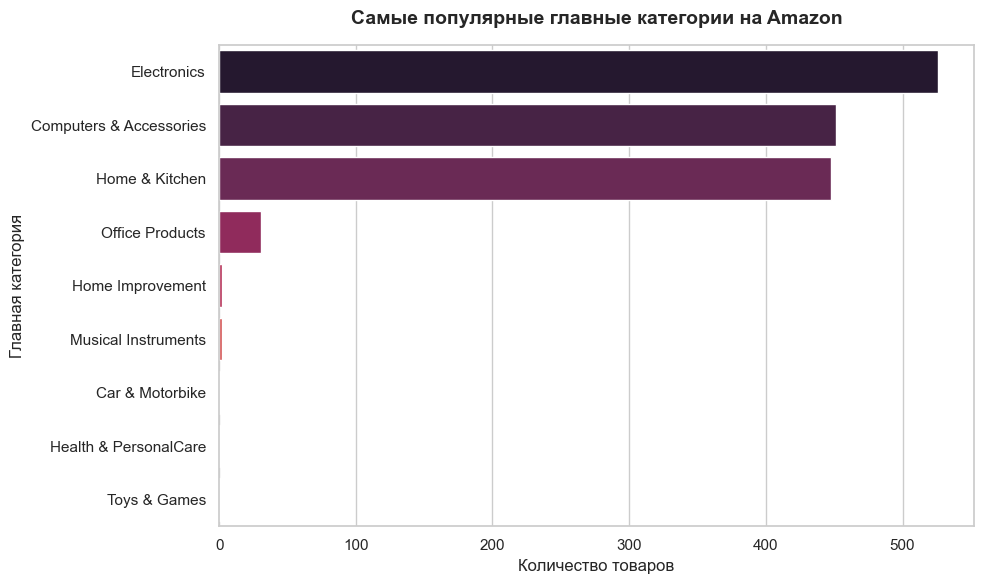

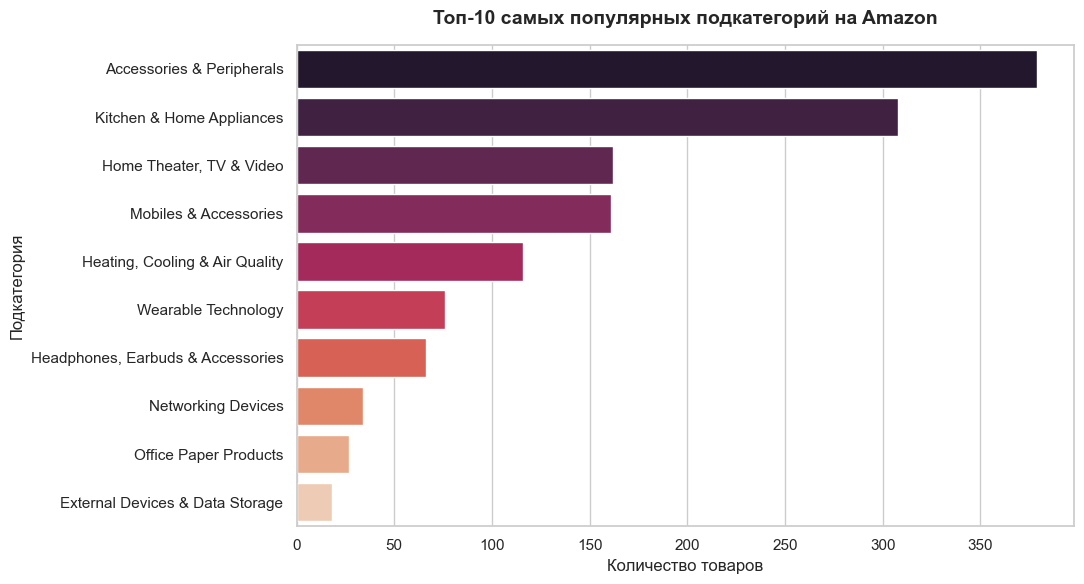

In [35]:
# Построим график "Самые популярные главные категории на Amazon"
main_cat_counts = (amazon_sales_2.groupby('main_category')['product_id'].count().reset_index(name='product_count')
                   .sort_values(by='product_count', ascending=False))

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=main_cat_counts,
    x='product_count',
    y='main_category',
    palette='rocket'
)

plt.title('Самые популярные главные категории на Amazon', fontsize=14, pad=15, weight='bold')
plt.xlabel('Количество товаров', fontsize=12)
plt.ylabel('Главная категория', fontsize=12)

plt.tight_layout()
plt.show()


# Построим график "Самые популярные подкатегории на Amazon"
sub_cat_counts = (amazon_sales_2.groupby('sub_category')['product_id'].count().reset_index(name='product_count')
    .sort_values(by='product_count', ascending=False).head(10))

plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=sub_cat_counts,
    x='product_count',
    y='sub_category',
    palette='rocket',
)

plt.title(
    'Топ-10 самых популярных подкатегорий на Amazon',
    fontsize=14,
    pad=15,
    weight='bold',
)
plt.xlabel('Количество товаров', fontsize=12)
plt.ylabel('Подкатегория', fontsize=12)

plt.tight_layout()
plt.show()

1. Лидеры среди главных категорий
Рынок на платформе распределен неравномерно, и явные лидеры выглядят следующим образом:

- Электроника — абсолютный лидер по количеству представленных товаров.
- Компьютеры и аксессуары - второе место.
- Дом и кухня - замыкает тройку лидеров.

Остальные категории показывают значительно меньшие объемы и сильно отстают от тройки лидеров.

2. Лидеры среди подкатегорий

- Аксессуары и периферийные устройства (лидер среди всех подкатегорий).
- Кухня и бытовая техника.
- Домашние кинотеатры и ТВ.

3. Аналитический вывод
Хотя главная категория «Компьютеры и аксессуары» занимает лишь второе место по общему количеству товаров, именно в ней находится самая популярная подкатегория на всей площадке «Аксессуары и периферийные устройства».
Это говорит о разной структуре спроса и ассортимента:
- в электронике популярность распределена более равномерно между большим числом востребованных подкатегорий.
- в компьютерах и аксессуарах ассортимент сконцентрирован вокруг одной суперпопулярной ниши (аксессуары), в то время как остальные подкатегории этой группы развиты слабее.

### Проведём ABC анализ категорий товаров
- А - категории, которые приносит 80% прибыли 
- В - категории, которые приносит ещё 15% прибыли 
- С - категории, которые приносят оставшиеся 5% прибыли 

In [38]:
# Группируем данные по категории и считаем сумму товаров
category_revenue = (amazon_sales_2.groupby('main_category')['discounted_price'].sum().reset_index(name='total_revenue'))

category_revenue = category_revenue.sort_values(by='total_revenue', ascending=False).reset_index(drop=True)

# Считаем нарастающую сумму по категориям
category_revenue['cumulative_revenue'] = category_revenue['total_revenue'].cumsum()
total_sales = category_revenue['total_revenue'].sum()
category_revenue['cumulative_percentage'] = (category_revenue['cumulative_revenue'] / total_sales) * 100

# Распределяем категории по классам в зависимости от выручки
def assign_abc(pct):
    if pct <= 80:
        return 'A'
    elif pct <= 95:
        return 'B'
    else:
        return 'C'

category_revenue['abc_class'] = category_revenue['cumulative_percentage'].apply(assign_abc)

category_revenue

,main_category,total_revenue,cumulative_revenue,cumulative_percentage,abc_class
0,Electronics,3138057.00,3138057.00,68.544479,A
1,Home & Kitchen,1044115.81,4182172.81,91.351067,B
2,Computers & Accessories,381272.62,4563445.43,99.679192,C
3,Office Products,9349.00,4572794.43,99.883402,C
4,Car & Motorbike,2339.00,4575133.43,99.934493,C
5,Musical Instruments,1276.00,4576409.43,99.962365,C
6,Health & PersonalCare,899.00,4577308.43,99.982001,C
7,Home Improvement,674.00,4577982.43,99.996724,C
8,Toys & Games,150.00,4578132.43,100.000000,C


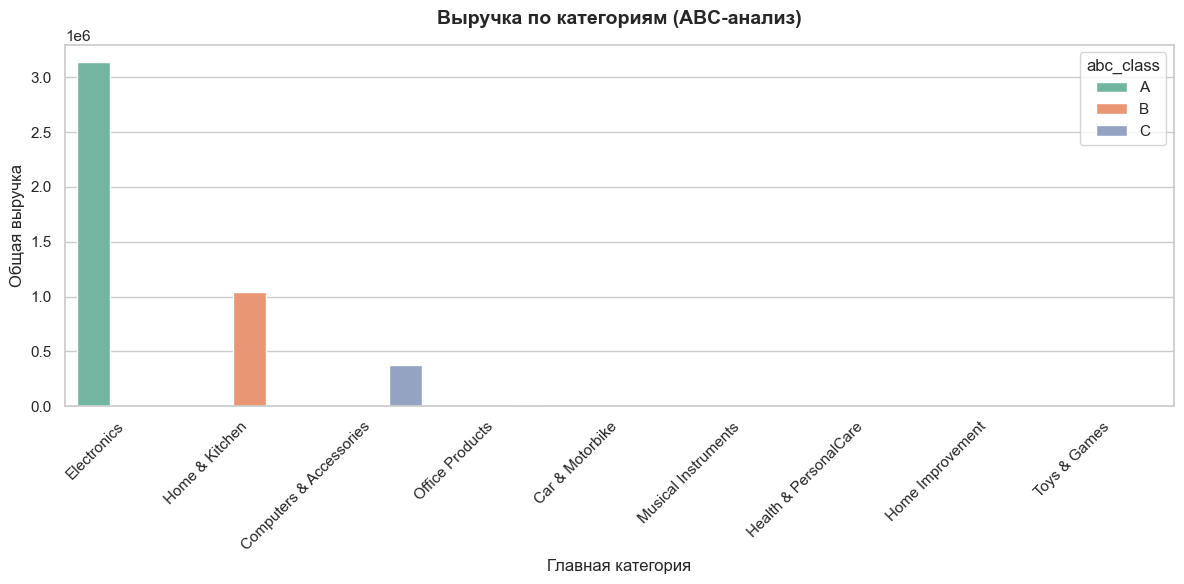

In [39]:
# Посмотрим выручку по категориям на графике
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=category_revenue,
    x='main_category',
    y='total_revenue',
    hue='abc_class',
    palette='Set2' 
)

plt.title('Выручка по категориям (ABC-анализ)', fontsize=14, pad=15, weight='bold')
plt.xlabel('Главная категория', fontsize=12)
plt.ylabel('Общая выручка', fontsize=12)

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

Электроника - главные драйвер бизнеса Amazon. Именно на неё приходится основной объем выручки, и ей нужно уделять первостепенное внимание.
Категория группы B - дом и кухня: промежуточная группа товаров, которая приносит стабильный, но уже меньший доход.
Все остальные категории относятся к группе C.Товаров в этих категориях может быть много, но суммарно денег они приносят мало.

### Проведём ABC анализ подкатегорий товаров
- А - категории, которые приносит 80% прибыли 
- В - категории, которые приносит ещё 15% прибыли 
- С - категории, которые приносят оставшиеся 5% прибыли

In [42]:
# Группируем данные по подкатегории и считаем сумму товаров
subcat_revenue = (amazon_sales_2.groupby(['main_category', 'sub_category'])['discounted_price'].sum().reset_index(name='total_revenue'))

subcat_revenue = (subcat_revenue.sort_values(by='total_revenue', ascending=False).head(10).reset_index(drop=True))

# Считаем нарастающую сумму по категориям
subcat_revenue['cumulative_revenue'] = subcat_revenue['total_revenue'].cumsum()
total_sales_top10 = subcat_revenue['total_revenue'].sum()
subcat_revenue['cumulative_percentage'] = (subcat_revenue['cumulative_revenue'] / total_sales_top10) * 100

# Распределяем категории по классам в зависимости от выручки
subcat_revenue['abc_class'] = subcat_revenue['cumulative_percentage'].apply(assign_abc)

subcat_revenue

,main_category,sub_category,total_revenue,cumulative_revenue,cumulative_percentage,abc_class
0,Electronics,"Home Theater, TV & Video",1685954.00,1685954.00,38.227819,A
1,Electronics,Mobiles & Accessories,1148582.00,2834536.00,64.271107,A
2,Home & Kitchen,Kitchen & Home Appliances,663149.14,3497685.14,79.307546,A
3,Home & Kitchen,"Heating, Cooling & Air Quality",373789.61,3871474.75,87.782962,B
4,Computers & Accessories,Accessories & Peripherals,184752.62,4056227.37,91.972098,B
5,Electronics,Wearable Technology,177817.00,4234044.37,96.003973,C
6,Electronics,"Headphones, Earbuds & Accessories",62576.00,4296620.37,97.422840,C
7,Computers & Accessories,External Devices & Data Storage,38725.00,4335345.37,98.300902,C
8,Computers & Accessories,Networking Devices,37688.00,4373033.37,99.155451,C
9,Computers & Accessories,Laptops,37247.00,4410280.37,100.000000,C


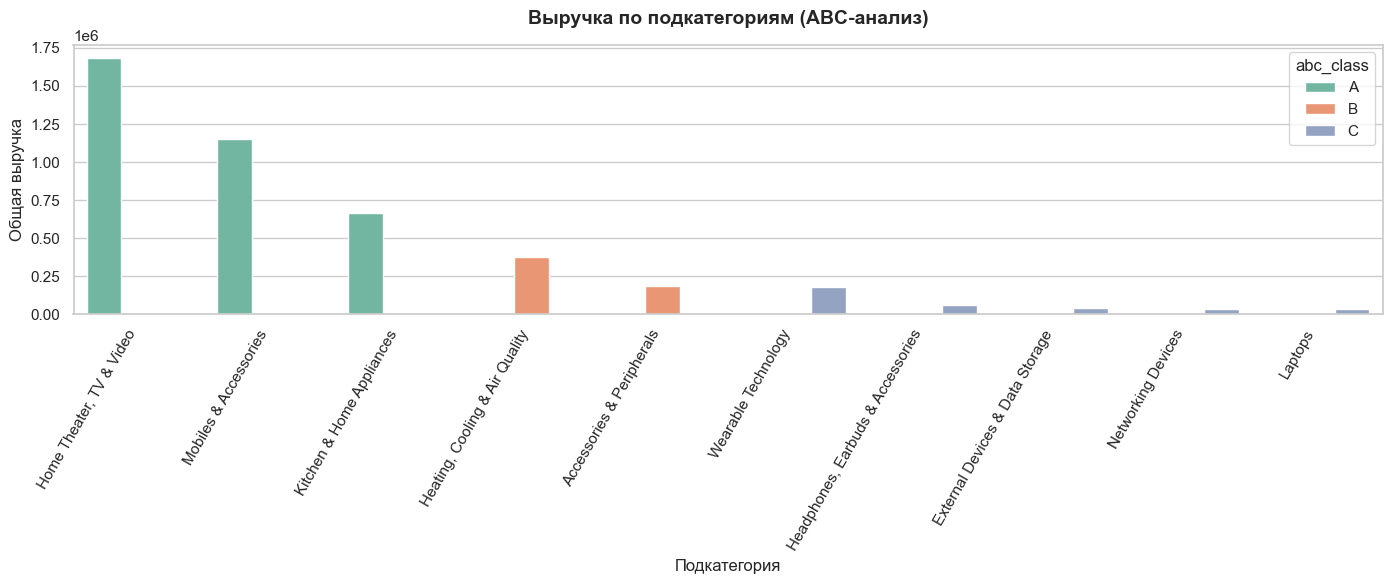

In [43]:
# Посмотрим выручку по подкатегориям на графике
plt.figure(figsize=(14, 6))

ax = sns.barplot(
    data=subcat_revenue,
    x='sub_category',
    y='total_revenue',
    hue='abc_class',
    palette='Set2'
)

plt.title('Выручка по подкатегориям (ABC-анализ)', fontsize=14, pad=15, weight='bold')
plt.xlabel('Подкатегория', fontsize=12)
plt.ylabel('Общая выручка', fontsize=12)

plt.xticks(rotation=60, ha='right')

plt.tight_layout()
plt.show()

"Домашние кинотеатры и ТВ", "мобильные телефоны и аксессуары", "кухня и бытовая техника" приносят Amazon 80% всей прибыли. Этим подкатегориямнужно уделять первостепенное внимание. 
Категория группы B - "отопление, охлаждение и качество воздуха" и "аксессуары и периферийные устройства"  промежуточная группа товаров, которая приносит стабильный, но уже меньший доход. 
Все остальные категории относятся к группе C.Товаров в этих категориях может быть много, но суммарно денег они приносят мало.
Отметим, что по числу заказов подкатегорию "аксессуары и периферийные устройства" - абсолютный лидер, но денег эта подкатегория приносит не так уж и много.

У нас есть таблица user_orders с помощью которой я хочу посмотреть, как зависят друг от друга цена товара и колличество покупок данного товара.

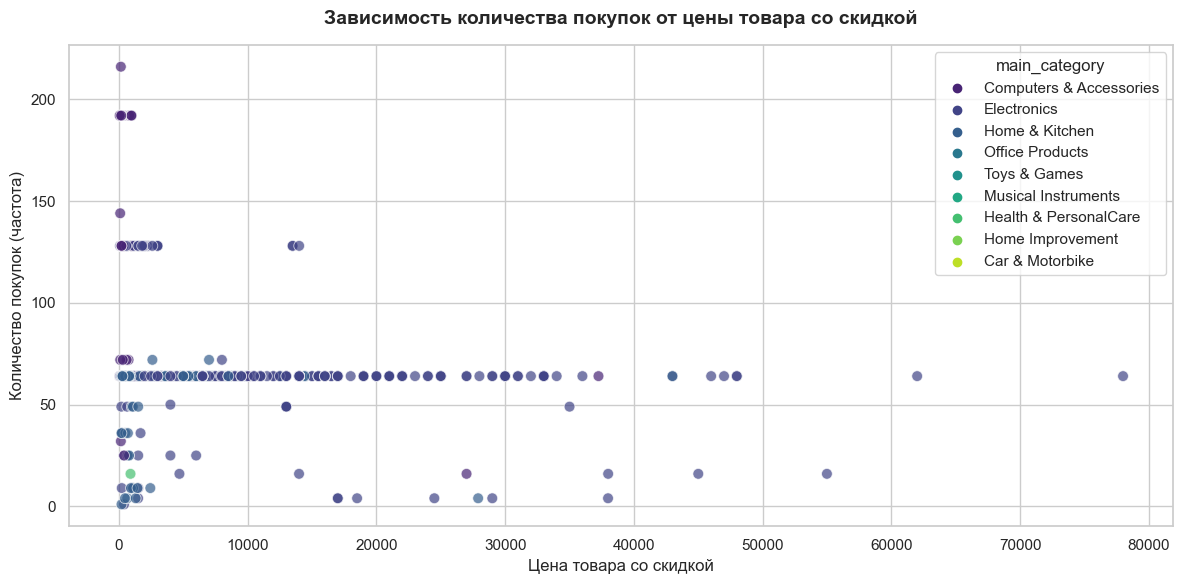

In [46]:
# Считаем количество покупок для каждого товара
product_summary = (user_orders.groupby(['product_id', 'product_name', 'main_category'])
    .agg(purchase_count=('product_id','count',),
     price=('discounted_price', 'first'), 
    ).reset_index())

# Строим график "Зависимость количества покупок от цены товара со скидкой"
plt.figure(figsize=(12, 6))

ax = sns.scatterplot(
    data=product_summary,
    x='price',
    y='purchase_count',
    hue='main_category',
    palette='viridis',  
    alpha=0.7,          
    s=60                
)

plt.title('Зависимость количества покупок от цены товара со скидкой', fontsize=14, pad=15, weight='bold')
plt.xlabel('Цена товара со скидкой', fontsize=12)
plt.ylabel('Количество покупок (частота)', fontsize=12)

plt.tight_layout()
plt.show()

Наибольщее число покупок наблюдается у товаров в ценовой категории до 10к, по возрастанию цены число покупок товара снижается.
Мы видим, что самые дорогостоящие покупки принадлежат к категории Электроника, что логично, ведь именно она приносит 80% прибыли амазону. Самый дорогостоящий товар это TV от фирмы Sony, он был куплен 64 раза.
Самый частопокупаемый товар относится к категории компьютеры и аксессуары, а именно это кабель Type-C от фирмы p Tron, он был куплен 216 раз.

### 2.2 Анализ рейтинга

In [49]:
# Посмотрим сколько у нас товаров в каждой категории рейтинга товаров

In [50]:
rating_counts = amazon_sales_2.groupby('rating_category')['product_id'].count().reset_index(name='rating_category_count').sort_values(by='rating_category_count', ascending=False)
rating_counts

,rating_category,rating_category_count
2,good,1104
1,fair,348
3,poor,6
0,excellent,5


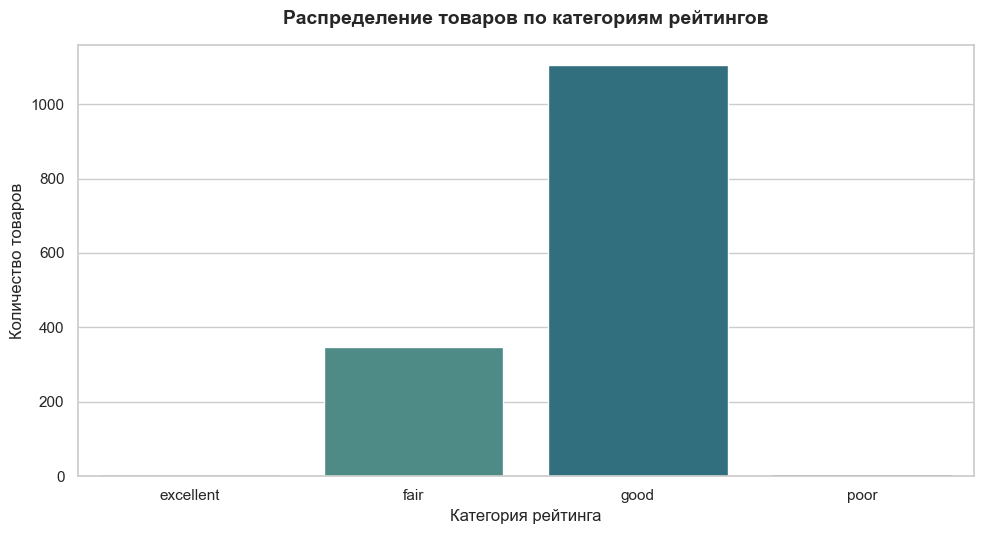

In [51]:
# Построим график категорий оценок товаров
plt.figure(figsize=(10, 5.5))

ax = sns.barplot(
    data=rating_counts,
    x='rating_category',
    y='rating_category_count',
    palette='crest' 
)

plt.title('Распределение товаров по категориям рейтингов', fontsize=14, pad=15, weight='bold')
plt.xlabel('Категория рейтинга', fontsize=12)
plt.ylabel('Количество товаров', fontsize=12)

plt.tight_layout()
plt.show()

Больше всего товаров на Amazon хорошего качества, т.е. их оценка от 4 до 4.8. В трое меньше товаров среднего качества с оценкой от 3 до 3.9. Очень плохих товаров, как и очень хороших на платформе единицы.

Теперь посмотрим как распределён рейтинг товаров.

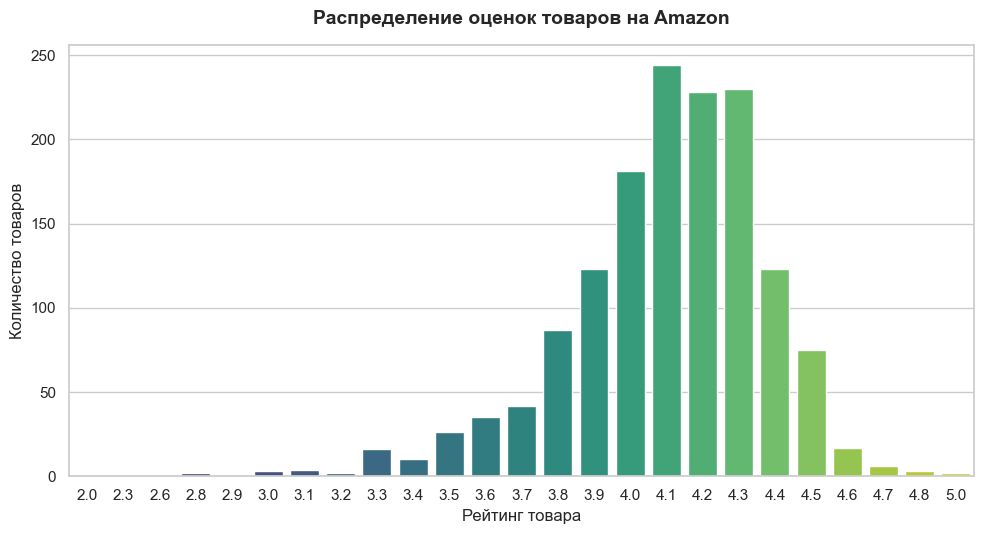

In [54]:
rating_distribution = (amazon_sales_2.groupby('rating')['product_id'].count().reset_index(name='product_count').sort_values(by='rating', ascending=True))

# Построим распределение оценок товаров
plt.figure(figsize=(10, 5.5))

ax = sns.barplot(
    data=rating_distribution,
    x='rating',
    y='product_count',
    palette='viridis'
)

plt.title('Распределение оценок товаров на Amazon', fontsize=14, pad=15, weight='bold')
plt.xlabel('Рейтинг товара', fontsize=12)
plt.ylabel('Количество товаров', fontsize=12)

plt.tight_layout()
plt.show()

Этот график подтверждает мой предыдущий вывод. Самая популярная оценка товара на Amazon 4.1. Товаров с таким рейтингом 244.

In [56]:
# Посмотрим скошенность распределения рейтинга товаров
rating_skew = amazon_sales_2['rating'].skew().round(2)

print(f'Коэффициент асимметрии для оценок: {rating_skew}')

Коэффициент асимметрии для оценок: -1.26


Распределение оценок довольно сильно скошено влево. Это значит, что абсолютное большинство товаров в наборе данных имеют оценки близкие к максимальным.

Низкие оценки  — это скорее исключения или точечные выбросы. Покупатели на Amazon в основном своей ставят товарам высокие баллы.

Теперь посмотрим распределение колличества отзывов на товары

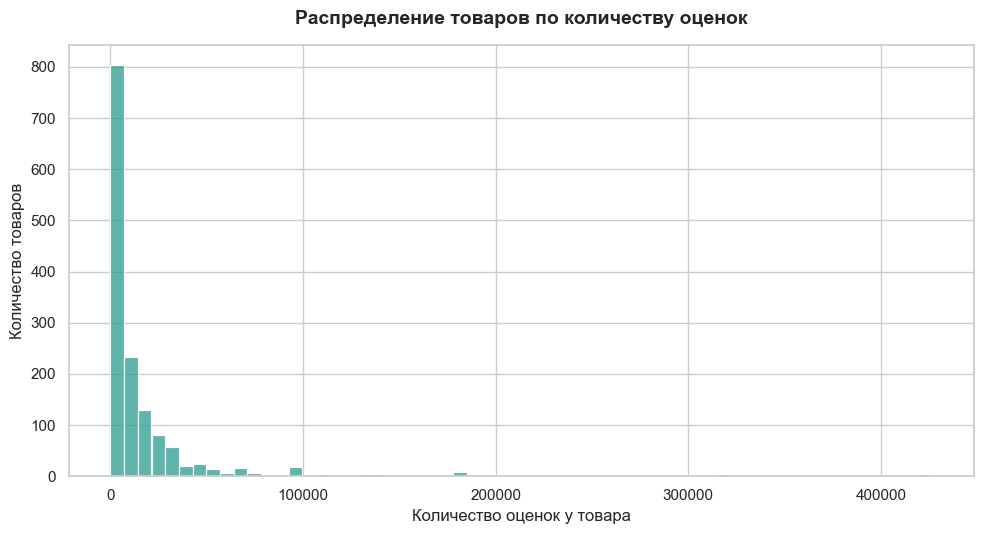

In [59]:
plt.figure(figsize=(10, 5.5))

ax = sns.histplot(
    data=amazon_sales_2,
    x='rating_count',
    bins=60,          
    color='#2A9D8F', 
    edgecolor='white'
)

plt.title('Распределение товаров по количеству оценок', fontsize=14, pad=15, weight='bold')
plt.xlabel('Количество оценок у товара', fontsize=12)
plt.ylabel('Количество товаров', fontsize=12)

plt.tight_layout()
plt.show();

Абсолютное большинство товаров имеют до 10к отзывов, все остальные товары имеют более 10 к отзывов, но всё, что больше 50к - уже выбросы. Интересно, что на площадке есть 4 товара с числом оценок более 400к отзывов.

Интересно будет посмотреть как отличается рейтинг товаров в зависимости от категории.

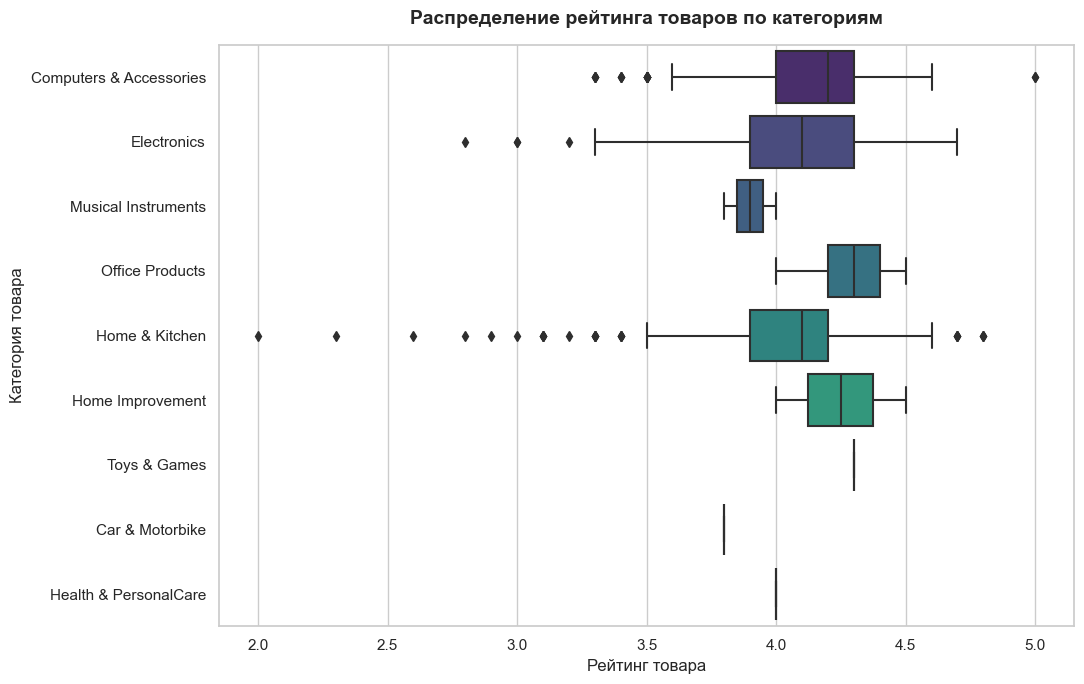

In [62]:
plt.figure(figsize=(11, 7))

ax = sns.boxplot(
    data=amazon_sales_2,
    x='rating',
    y='main_category',
    palette='viridis'
)

plt.title('Распределение рейтинга товаров по категориям', fontsize=14, pad=15, weight='bold')
plt.xlabel('Рейтинг товара', fontsize=12)
plt.ylabel('Категория товара', fontsize=12)

plt.tight_layout()
plt.show()

В таких категориях, как «Игры и игрушки», «Автомобили и мотоциклы» и «Здоровье и личная гигиена», рейтинги товаров держатся в узком диапазоне и совсем нет выбросов. Это связано с тем, что в этих категориях очень мало покупок, поэтому, эти товары просто имеют по одному отзыву.

Категории «Благоустройство дома» и «Офисные товары» также демонстрируют  стабильные показатели. Дело в том, что в этих категориях всего по 2 отзыва.

Большинство товаров в категориях «Компьютеры и аксессуары» и «Электроника» сосредоточено в диапазоне 3.6 – 4.6.При этом в данных сегментах встречаются как абсолютные максимумы (5.0), так и заметные провалы до 2.8.

Товары для «Дома и кухни» отличаются самым широким распределением оценок: максимальные значения достигают 4.75, а минимальные падают до 2.0 (что является абсолютным антирекордом среди всех товаров).Тем не менее, основная масса позиций в этой категории концентрируется в диапазоне 3.8 – 4.6.

Теперь посмотрим как отличается рейтинг товаров в подкатегориях.

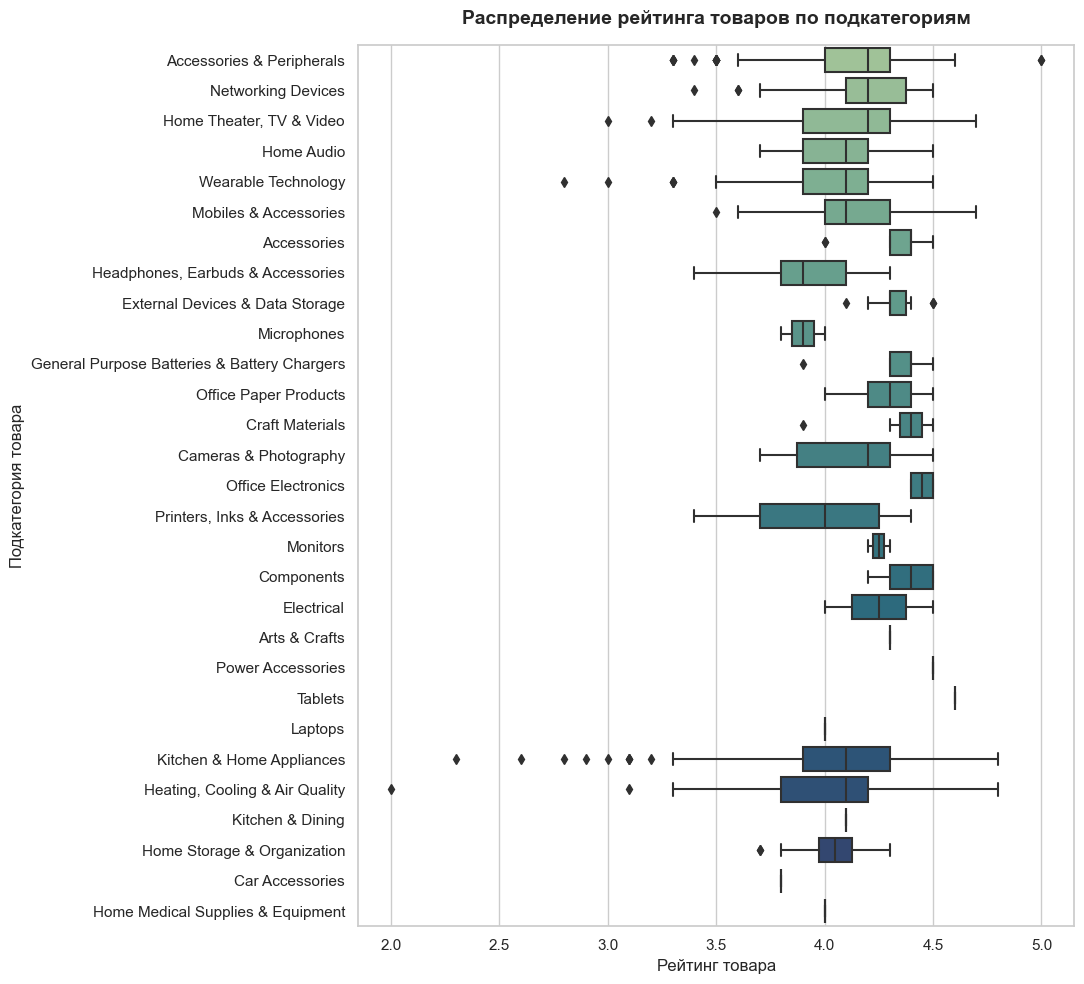

In [65]:
plt.figure(figsize=(11, 10))

ax = sns.boxplot(
    data=amazon_sales_2,
    x='rating',
    y='sub_category',
    palette='crest' 
)

plt.title('Распределение рейтинга товаров по подкатегориям', fontsize=14, pad=15, weight='bold')
plt.xlabel('Рейтинг товара', fontsize=12)
plt.ylabel('Подкатегория товара', fontsize=12)

plt.tight_layout()
plt.show()

Видим, что товар с самым высоким рейтингом относится к подкатегории "Аксессуары и периферия", но важно отметить, что это выброс в подкатегории а не правило. Товар с самым низким рейтингом принадлежит подкатегории "Отопление, охлаждение и качество воздуха".

### 2.3 Анализ скидочной компании

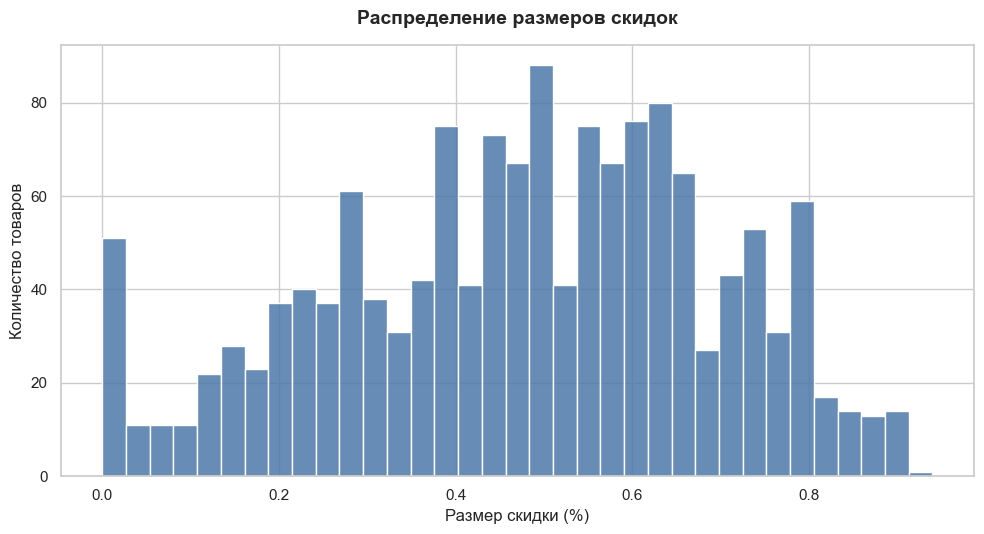

In [68]:
# Посмотрим на распределение скидок
plt.figure(figsize=(10, 5.5))

ax = sns.histplot(
    data=amazon_sales_2,
    x='discount_percentage',
    bins=35,           
    color='#4C78A8',   
    alpha=0.85,        
    edgecolor='white'  
)

plt.title('Распределение размеров скидок', fontsize=14, pad=15, weight='bold')
plt.xlabel('Размер скидки (%)', fontsize=12)
plt.ylabel('Количество товаров', fontsize=12)

plt.tight_layout()
plt.show()

In [69]:
# Посмотрим скошенность распределения рейтинга товаров
discount_skew = amazon_sales_2['discount_percentage'].skew().round(2)

print(f'Коэффициент асимметрии для оценок: {discount_skew}')

Коэффициент асимметрии для оценок: -0.29


Распределение оценок имеет небольшую скошеннось влево. Это говорит о том, что большая часть скидок - большие скидки. Но серьезных перекосов в данных нет.

Посмотрим как распределены скидки внутри каждой категории

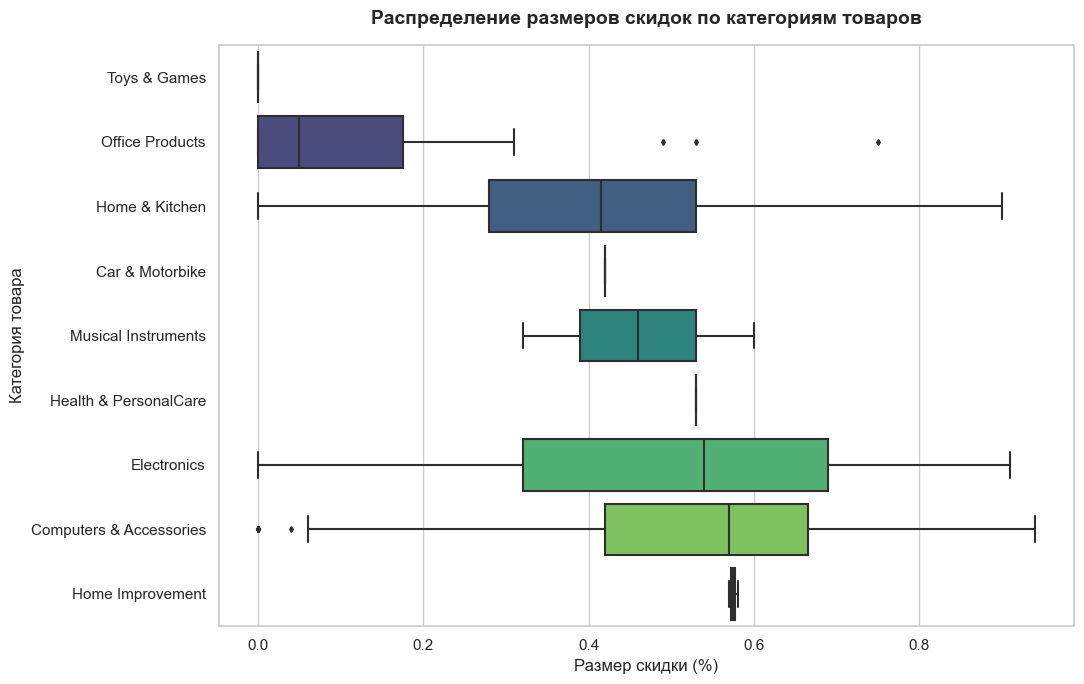

In [72]:
median_order = (amazon_sales_2.groupby('main_category')['discount_percentage'].median().sort_values(ascending=True).index)

plt.figure(figsize=(11, 7))

ax = sns.boxplot(
    data=amazon_sales_2,
    x='discount_percentage',
    y='main_category',
    order=median_order,  
    palette='viridis',
    fliersize=3,  
)

plt.title(
    'Распределение размеров скидок по категориям товаров',
    fontsize=14,
    pad=15,
    weight='bold',
)
plt.xlabel('Размер скидки (%)', fontsize=12)
plt.ylabel('Категория товара', fontsize=12)

plt.tight_layout()
plt.show()

Интереснее всего тут будет посмотреть на длинные ящики, т.к. это категории с большим колличеством товаров и они более показательные.
Больше всего скидки в категории "Компютеры и аксессуары". На втором месте самая высокоприбыльная категория для Amazon - "Электроника". При этом, в категории есть как и очень маленькие, так и очень большие скидки. 
Также как и в категории "Дом и кухня", но тут в среднем скидки по категории меньше, чем вышеперечисленных категориях.

Теперь посмотрим, как скидки распределились в подкатегориях

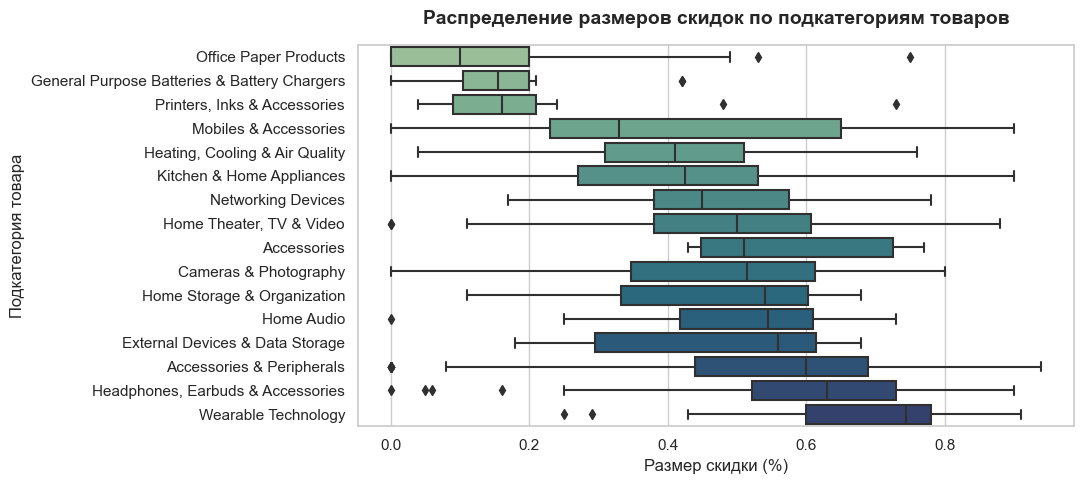

In [75]:
# Посмотрим только по тем подкатегориям, где больше 10 товаров
filtered_data = amazon_sales_2.groupby('sub_category').filter(lambda x: len(x) > 10)

median_order_sub = (filtered_data.groupby('sub_category')['discount_percentage'].median().sort_values(ascending=True).index)

plt.figure(figsize=(11, 5))

ax = sns.boxplot(
    data=filtered_data,
    x='discount_percentage',
    y='sub_category',
    order=median_order_sub,  
    palette='crest'          
)

plt.title('Распределение размеров скидок по подкатегориям товаров', fontsize=14, pad=15, weight='bold')
plt.xlabel('Размер скидки (%)', fontsize=12)
plt.ylabel('Подкатегория товара', fontsize=12)

plt.tight_layout()
plt.show()

А Вы успели себе урвать умные часы или умное кольцо по скидкам на Amazon?
Может быть хотя бы новые наушники? Нет?
Ну может хотья бы новую мышку и клаву?

Посмотрим на распределение суммы скидки на товары

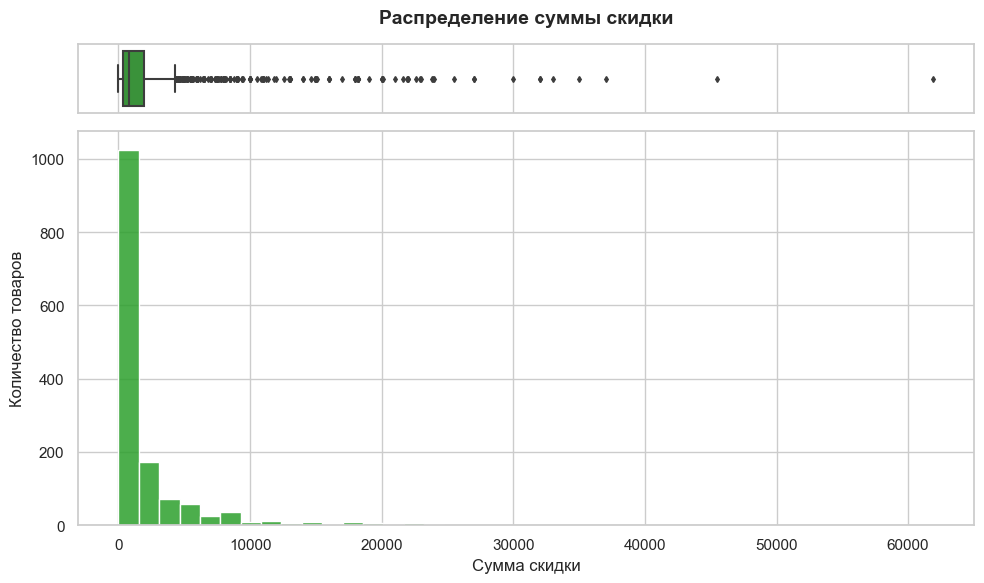

In [78]:
fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': (.15, .85)})

sns.boxplot(
    data=amazon_sales_2,
    x='discount_sum',
    ax=ax_box,
    color='#2CA02C',
    fliersize=3
)
ax_box.set(xlabel='')  
ax_box.set_title('Распределение суммы скидки', fontsize=14, pad=15, weight='bold')

sns.histplot(
    data=amazon_sales_2,
    x='discount_sum',
    bins=40,
    color='#2CA02C',
    alpha=0.85,          
    edgecolor='white',   
    ax=ax_hist
)

ax_hist.set_xlabel('Сумма скидки', fontsize=12)
ax_hist.set_ylabel('Количество товаров', fontsize=12)

plt.tight_layout()
plt.show()

Абсолюное большинство товаров были со скидкой от 370 до 1959 ₹

### 2.4 Анализ клиентской базы

In [81]:
# Посмотрим на самых активных пользователей Amazon
top_users = (user_orders.groupby(['user_id', 'user_name']).agg(order_count=('product_id', 'count'))
    .reset_index().sort_values(by='order_count', ascending=False))

# Топ-10 самых частых клиентов
top_users.head(10)

,user_id,user_name,order_count
1822,AE55KTFVNXYFD5FPYWP2OUPEYNPQ,Sethu madhav,11
10905,AENNAVVG4GBJKDQKJXQUEKQKTXGQ,Amazon Customer,11
38282,AG5DWPD54QGSLWJ6QUFERLPNAX4Q,E.C.GEORGE,11
38291,AG5DWPD54QGSLWJ6QUFERLPNAX4Q,indrajyoti d.,10
65225,AHMGAC6QM62UXNEOCZIHLHSXPP2Q,Justice ⚖️,10
18594,AF355FTXYAKFH5NYPRTE7SL3WO3Q,indrajyoti d.,10
65224,AHMGAC6QM62UXNEOCZIHLHSXPP2Q,E.C.GEORGE,10
11428,AEOKB3ECJUM6UQOBFKMEMQVVHL4A,Amazon Customer,10
26004,AFHROSCGIXUPV3FYQ7H5QOD46Q7Q,Justice ⚖️,10
26003,AFHROSCGIXUPV3FYQ7H5QOD46Q7Q,E.C.GEORGE,10


Видим, что имена повторяются, но при этом user_id разный. Либо клиенты имеют разные аккаунты с одним именем, либо тёзки.

Посмотрим еще просто по имени

In [83]:
# Посмотрим на самых активных пользователей Amazon (по имени) и за одно посмотрим на их траты
top_users = (user_orders.groupby('user_name').agg(order_count=('product_id', 'count'),       
                                                  total_spent=('discounted_price', 'sum')).reset_index().sort_values(by='order_count', ascending=False))

# Топ-10 самых частых клиентов
top_users.head(10)

,user_name,order_count,total_spent
534,Amazon Customer,5008,14275657.28
3946,Placeholder,472,1918784.00
2723,Kindle Customer,184,263456.00
4387,Rajesh,176,716912.00
1550,Deepak,134,129850.00
4706,Rohit,128,104432.00
4051,Prashant,120,192784.00
913,Arun,120,325744.00
557,Amit,99,217387.00
3159,Manoj Kumar,96,123470.16


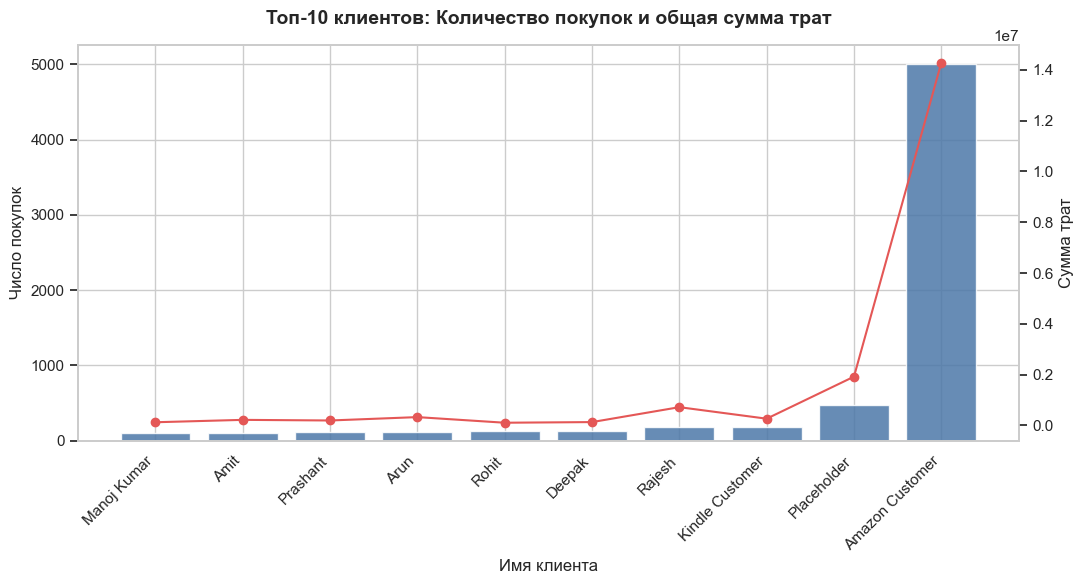

In [84]:
top_10_users = top_users.head(10).sort_values(by='order_count', ascending=True)

fig, ax1 = plt.subplots(figsize=(11, 6))

ax1.bar(
    top_10_users['user_name'],
    top_10_users['order_count'],
    color='#4C78A8',
    alpha=0.85,
    label='Количество покупок'
)
ax1.set_xlabel('Имя клиента', fontsize=12)
ax1.set_ylabel('Число покупок', fontsize=12)

plt.xticks(rotation=45, ha='right')

ax2 = ax1.twinx()
ax2.plot(
    top_10_users['user_name'],
    top_10_users['total_spent'],
    color='#E45756',
    marker='o',
    label='Сумма трат'
)
ax2.set_ylabel('Сумма трат', fontsize=12)
ax2.grid(False)  

plt.title('Топ-10 клиентов: Количество покупок и общая сумма трат', fontsize=14, pad=15, weight='bold')

plt.tight_layout()
plt.show()

К сожалению, большинство клиентов не заполнили полноценно свой профиль и мы не можем достоверно оценить самых ценных из них.

# 3. Выводы

Лидеры Amazon:
- Электроника — абсолютный лидер по количеству представленных товаров.
- Компьютеры и аксессуары - второе место.
- Дом и кухня - замыкает тройку лидеров.
Остальные категории показывают значительно меньшие объемы и сильно отстают от тройки лидеров.

Лидеры среди подкатегорий:
- Аксессуары и периферийные устройства (лидер среди всех подкатегорий).
- Кухня и бытовая техника.
- Домашние кинотеатры и ТВ.

! Хотя главная категория «Компьютеры и аксессуары» занимает лишь второе место по общему количеству товаров, именно в ней находится самая популярная подкатегория на всей площадке «Аксессуары и периферийные устройства».
- в электронике популярность распределена более равномерно между большим числом востребованных подкатегорий.
- в компьютерах и аксессуарах ассортимент сконцентрирован вокруг одной суперпопулярной ниши (аксессуары), в то время как остальные подкатегории этой группы развиты слабее.

#### Электроника - главные драйвер бизнеса Amazon. 
Именно на неё приходится основной объем выручки, и ей нужно уделять первостепенное внимание. 

Категория группы B - дом и кухня: промежуточная группа товаров, которая приносит стабильный, но уже меньший доход. 

Все остальные категории относятся к группе C. Товаров в этих категориях может быть много, но суммарно денег они приносят мало.

#### "Домашние кинотеатры и ТВ", "мобильные телефоны и аксессуары", "кухня и бытовая техника" приносят Amazon 80% всей прибыли. 

Категория группы B - "отопление, охлаждение и качество воздуха" и "аксессуары и периферийные устройства" промежуточная группа товаров, которая приносит стабильный, но уже меньший доход. 

Все остальные категории относятся к группе C.Товаров в этих категориях может быть много, но суммарно денег они приносят мало. Отметим, что по числу заказов подкатегорию "аксессуары и периферийные устройства" - абсолютный лидер, но денег эта подкатегория приносит не так уж и много.

Наибольщее число покупок наблюдается у товаров в ценовой категории до 10к, по возрастанию цены число покупок товара снижается. Мы видим, что самые дорогостоящие покупки принадлежат к категории Электроника, что логично, ведь именно она приносит 80% прибыли амазону. 

- Самый дорогостоящий товар это TV от фирмы Sony, он был куплен 64 раза. 

- Самый частопокупаемый товар относится к категории компьютеры и аксессуары, а именно это кабель Type-C от фирмы p Tron, он был куплен 216 раз.

*** Больше всего товаров на Amazon хорошего качества, т.е. их оценка от 4 до 4.8. В трое меньше товаров среднего качества с оценкой от 3 до 3.9. Очень плохих товаров, как и очень хороших на платформе единицы.

Абсолютное большинство товаров имеют до 10к отзывов, все остальные товары имеют более 10 к отзывов, но всё, что больше 50к - уже выбросы. Интересно, что на площадке есть 4 товара с числом оценок более 400к отзывов.

- В таких категориях, как «Игры и игрушки», «Автомобили и мотоциклы» и «Здоровье и личная гигиена», рейтинги товаров держатся в узком диапазоне и совсем нет выбросов. Это связано с тем, что в этих категориях очень мало покупок, поэтому, эти товары просто имеют по одному отзыву.

- Категории «Благоустройство дома» и «Офисные товары» также демонстрируют стабильные показатели. Дело в том, что в этих категориях всего по 2 отзыва.

- Большинство товаров в категориях «Компьютеры и аксессуары» и «Электроника» сосредоточено в диапазоне 3.6 – 4.6.При этом в данных сегментах встречаются как абсолютные максимумы (5.0), так и заметные провалы до 2.8.

- Товары для «Дома и кухни» отличаются самым широким распределением оценок: максимальные значения достигают 4.75, а минимальные падают до 2.0 (что является абсолютным антирекордом среди всех товаров).Тем не менее, основная масса позиций в этой категории концентрируется в диапазоне 3.8 – 4.6.

Больше всего скидки в категории "Компютеры и аксессуары". На втором месте самая высокоприбыльная категория для Amazon - "Электроника". При этом, в категории есть как и очень маленькие, так и очень большие скидки. Также как и в категории "Дом и кухня", но тут в среднем скидки по категории меньше, чем вышеперечисленных категориях.

- Абсолюное большинство товаров были со скидкой от 370 до 1959 ₹